# 4.3.- Clasificación de MNIST con Keras

En este notebook entrenaremos un **clasificador MLP** sobre el dataset **MNIST** aplicando las principales técnicas vistas en clase:

- Normalización y preprocesamiento de datos  
- Arquitectura **Sequential** con *Batch Normalization* y *Dropout*  
- Uso de **callbacks** (`EarlyStopping`, `ModelCheckpoint`, `ReduceLROnPlateau`)  
- **Guardado** del mejor modelo entrenado  

El objetivo es comprender cómo aplicar estos elementos en un flujo completo de entrenamiento.

La función de pérdida será la **entropía cruzada categórica**:

$$
\mathcal{L}(y, \hat{y}) = - \sum_{i=1}^{K} y_i \log(\hat{y}_i)
$$

Y la métrica principal será la **exactitud (accuracy)**:

$$
\text{Accuracy} = \frac{\text{Número de aciertos}}{\text{Número total de muestras}}
$$

In [1]:
# Importaciones básicas
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers, callbacks
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# Configuración global de gráficos
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.grid"] = True

# Semilla para reproducibilidad
np.random.seed(33)
keras.utils.set_random_seed(33)

## Carga y exploración de MNIST

El dataset **MNIST** contiene imágenes de dígitos escritos a mano (0–9) en escala de grises de tamaño $28 \times 28$.  
Cada imagen puede representarse como una matriz de 784 valores de intensidad entre 0 y 255.

Dividiremos los datos en:

- **60 000** imágenes para entrenamiento  
- **10 000** imágenes para prueba  

Exploraremos también algunos ejemplos visualmente.

Dimensiones de X_train: (60000, 28, 28)
Dimensiones de y_train: (60000,)
Dimensiones de X_test: (10000, 28, 28)


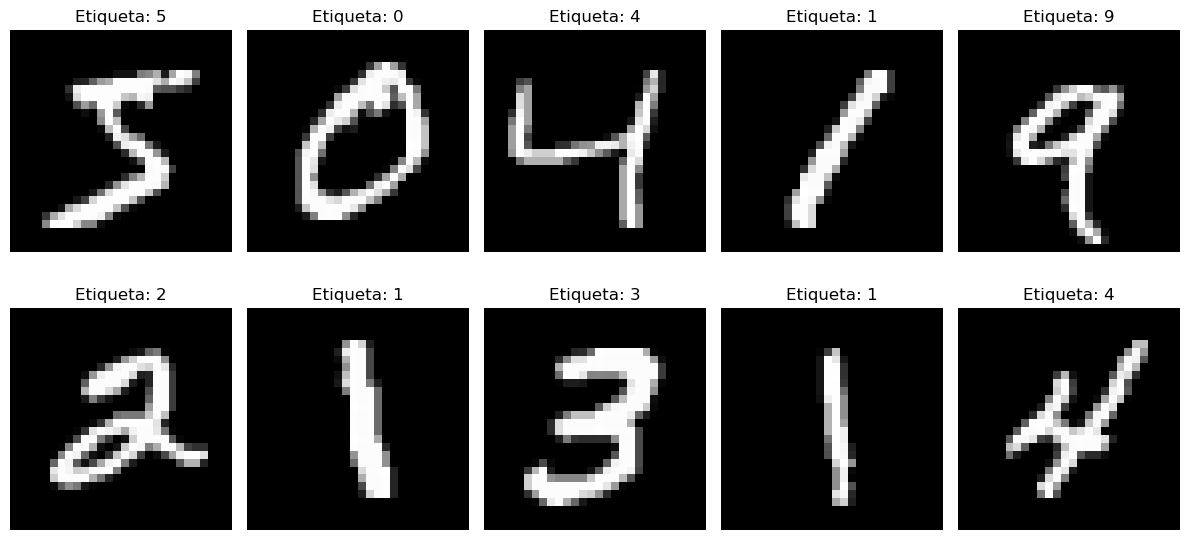

In [2]:
# Cargar dataset MNIST
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

# Dimensiones
print("Dimensiones de X_train:", X_train.shape)
print("Dimensiones de y_train:", y_train.shape)
print("Dimensiones de X_test:", X_test.shape)

# Mostrar algunos ejemplos
fig, axes = plt.subplots(2, 5)
for i, ax in enumerate(axes.flat):
    ax.imshow(X_train[i], cmap="gray")
    ax.set_title(f"Etiqueta: {y_train[i]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Preprocesamiento de datos

Antes de entrenar una red neuronal, es importante **escalar** y **formatear** correctamente los datos.

1. **Normalización:**  
   Las imágenes de MNIST tienen valores entre $0$ y $255$.  
   Escalamos a $[0, 1]$ mediante:

   $$
   X_{\text{norm}} = \frac{X}{255}
   $$

2. **Aplanamiento (Flatten):**  
   Las redes densas esperan vectores, no matrices.  
   Cada imagen de $28\times28$ se convertirá en un vector de $784$ componentes.

3. **Codificación one-hot:**  
   Las etiquetas $y$ se convierten en vectores binarios de tamaño 10 (uno por clase),  
   donde el dígito correcto tiene valor 1 y el resto 0.

In [3]:
# Normalización
X_train = X_train.astype("float32") / 255.0
X_test  = X_test.astype("float32") / 255.0

# Aplanar imágenes (28x28 → 784)
X_train = X_train.reshape(-1, 28*28)
X_test  = X_test.reshape(-1, 28*28)

# Codificación one-hot de etiquetas
num_classes = 10
y_train = keras.utils.to_categorical(y_train, num_classes)
y_test  = keras.utils.to_categorical(y_test, num_classes)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

X_train: (60000, 784)
y_train: (60000, 10)


## Definición del modelo MLP

Crearemos una red neuronal **feed-forward (MLP)** con la arquitectura:

1. **Capa de entrada:** 784 neuronas (una por píxel).  
2. **Capa oculta 1:** 256 neuronas, activación `ReLU`.  
3. **Batch Normalization:** normaliza las activaciones internas:  

   $$
   \hat{x}_i = \frac{x_i - \mu_\text{batch}}{\sqrt{\sigma_\text{batch}^2 + \epsilon}}
   $$

4. **Dropout:** apaga aleatoriamente un porcentaje de neuronas durante el entrenamiento  
   para evitar *overfitting*.  

5. **Capa de salida:** 10 neuronas con `softmax`, que asigna probabilidades:

   $$
   \hat{y}_k = \frac{e^{z_k}}{\sum_{j=1}^{10} e^{z_j}}
   $$

In [4]:
# Definición del modelo secuencial
model = keras.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(256, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(10, activation="softmax")
])

# Resumen del modelo
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 256)                 │         200,960 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           2,570 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 204,554 (799.04 KB)

 Trainable params: 204,042 (797.04 KB)

 Non-trainable params: 512 (2.00 KB)

## Compilación y configuración de Callbacks

Antes de entrenar, debemos **compilar** el modelo, definiendo:

- **Optimizador:** `Adam`, con tasa de aprendizaje adaptativa.  
- **Función de pérdida:** `categorical_crossentropy`  
- **Métricas:** `accuracy`

Además, emplearemos tres *callbacks* clave:

1. **EarlyStopping:**  
   Detiene el entrenamiento cuando la pérdida de validación deja de mejorar.  

2. **ModelCheckpoint:**  
   Guarda automáticamente el mejor modelo (según validación).  

3. **ReduceLROnPlateau:**  
   Reduce la tasa de aprendizaje si el modelo se estanca.  

Estos mecanismos ayudan a evitar el **sobreajuste** y optimizan el tiempo de entrenamiento.

In [5]:
# Compilar el modelo
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# Definición de callbacks
early_stop = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

checkpoint = callbacks.ModelCheckpoint(
    "nmist_base_model.keras",
    monitor="val_loss",
    save_best_only=True
)

reduce_lr = callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-5
)

callback_list = [early_stop, checkpoint, reduce_lr]

## Entrenamiento del modelo

Entrenaremos el modelo durante un número máximo de épocas, pero el *callback* `EarlyStopping`  
detendrá el proceso cuando la pérdida de validación deje de mejorar.

Usaremos un **20 % de los datos de entrenamiento** para validación (`validation_split=0.2`).

Durante el entrenamiento, los *callbacks* harán lo siguiente:

- **EarlyStopping:** detiene antes de sobreajustar.  
- **ModelCheckpoint:** guarda el mejor modelo.  
- **ReduceLROnPlateau:** reduce la tasa de aprendizaje automáticamente.

In [6]:
# Entrenamiento
history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=128,
    callbacks=callback_list,
    verbose=0
)

## Evolución de la pérdida y la exactitud

Representamos las curvas de entrenamiento y validación para analizar el comportamiento del modelo.  
Una buena generalización se observa cuando ambas curvas convergen sin gran separación.

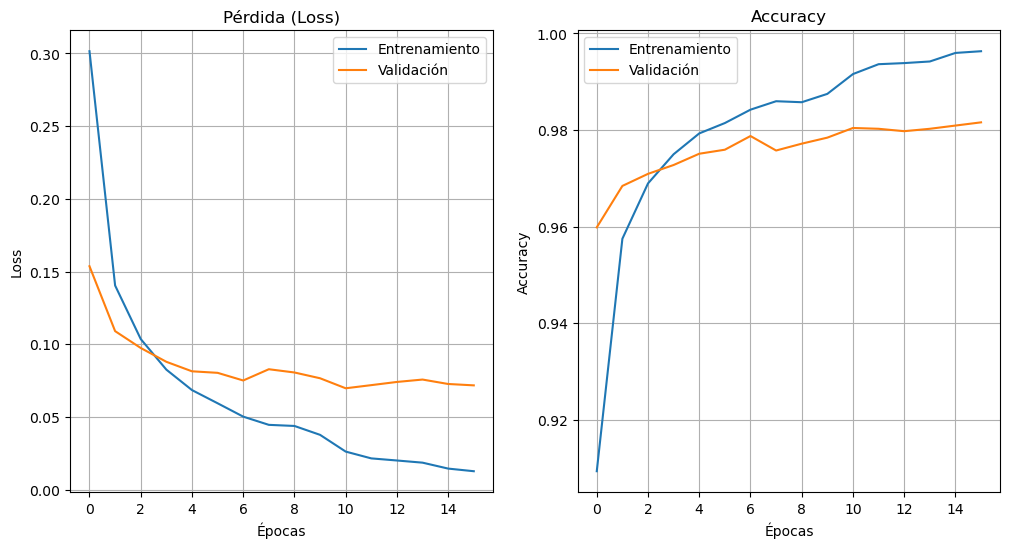

In [7]:
# Gráfico de pérdida y accuracy
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

# Pérdida
ax[0].plot(history.history["loss"], label="Entrenamiento")
ax[0].plot(history.history["val_loss"], label="Validación")
ax[0].set_title("Pérdida (Loss)")
ax[0].set_xlabel("Épocas")
ax[0].set_ylabel("Loss")
ax[0].legend()

# Exactitud
ax[1].plot(history.history["accuracy"], label="Entrenamiento")
ax[1].plot(history.history["val_accuracy"], label="Validación")
ax[1].set_title("Accuracy")
ax[1].set_xlabel("Épocas")
ax[1].set_ylabel("Accuracy")
ax[1].legend()

plt.show()

## Evaluación sobre el conjunto de prueba

Una vez completado el entrenamiento, evaluamos el rendimiento del modelo sobre el conjunto de **test**.

Esto nos permitirá estimar su capacidad de generalización fuera de los datos de entrenamiento.

Calcularemos:
- **Loss (pérdida)**  
- **Accuracy (exactitud)**  
- **Matriz de confusión** y **reporte de clasificación**

In [8]:
# Evaluación del modelo en test
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Loss en test: {test_loss:.4f}")
print(f"Accuracy en test: {test_acc:.4f}")

# Predicciones
y_pred = model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = np.argmax(y_test, axis=1)

Loss en test: 0.0621
Accuracy en test: 0.9813
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 725us/step
